In [43]:
import os

try:
  os.chdir('../Rで学ぶベイズ統計学入門')
except:
  pass

path = os.getcwd()

path

'/Users/takanohiroshi/Library/CloudStorage/OneDrive-個人用/Documenten/GitHub/Rで学ぶベイズ統計学入門'

In [44]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib


In [45]:
df = pd.read_csv("studentdata.txt", sep="\t")
df0 = df

In [46]:
df.head()

,Student,Height,Gender,Shoes,Number,Dvds,ToSleep,WakeUp,Haircut,Job,Drink
0,1,67.0,female,10.0,5.0,10.0,-2.5,5.5,60.0,30.0,water
1,2,64.0,female,20.0,7.0,5.0,1.5,8.0,0.0,20.0,pop
2,3,61.0,female,12.0,2.0,6.0,-1.5,7.5,48.0,0.0,milk
3,4,61.0,female,3.0,6.0,40.0,2.0,8.5,10.0,0.0,water
4,5,70.0,male,4.0,5.0,6.0,0.0,9.0,15.0,17.5,pop


In [47]:
df["Drink"].unique()

array(['water', 'pop', 'milk', nan], dtype=object)

In [48]:
drink_counts = df["Drink"].value_counts()
drink_counts

Drink
water    355
pop      178
milk     113
Name: count, dtype: int64

Text(0.5, 1.0, 'Drink Frequency')

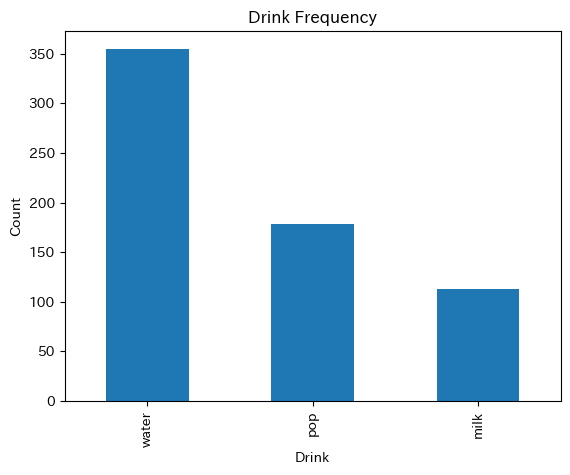

In [49]:
drink_counts.plot(kind="bar")

plt.xlabel("Drink")
plt.ylabel("Count")
plt.title("Drink Frequency")

In [50]:
df["Hours_of_sleep"] = df["WakeUp"] - df["ToSleep"]

In [51]:
df

,Student,Height,Gender,Shoes,Number,Dvds,ToSleep,WakeUp,Haircut,Job,Drink,Hours_of_sleep
0,1,67.0,female,10.0,5.0,10.0,-2.5,5.5,60.0,30.0,water,8.0
1,2,64.0,female,20.0,7.0,5.0,1.5,8.0,0.0,20.0,pop,6.5
2,3,61.0,female,12.0,2.0,6.0,-1.5,7.5,48.0,0.0,milk,9.0
3,4,61.0,female,3.0,6.0,40.0,2.0,8.5,10.0,0.0,water,6.5
4,5,70.0,male,4.0,5.0,6.0,0.0,9.0,15.0,17.5,pop,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...
652,653,71.0,female,15.0,8.0,25.0,-1.0,9.0,0.0,0.0,water,10.0
653,654,66.0,female,25.0,5.0,1.0,-1.5,9.0,0.0,12.0,pop,10.5
654,655,67.0,female,10.0,7.0,10.0,0.0,9.5,0.0,10.0,pop,9.5
655,656,68.0,male,3.0,5.0,15.0,2.5,7.7,15.0,20.0,pop,5.2


In [10]:
import pandas as pd

# サンプルデータ（24時をまたぐケースを含む）
df2 = pd.DataFrame({
    "bedtime": ["23:30", "00:15", "22:45"],
    "waketime": ["06:30", "07:00", "05:15"]
})

print(df2)


  bedtime waketime
0   23:30    06:30
1   00:15    07:00
2   22:45    05:15


In [11]:
df2["bedtime"] = pd.to_datetime(df2["bedtime"], format="%H:%M")
df2["waketime"] = pd.to_datetime(df2["waketime"], format="%H:%M")
df2

,bedtime,waketime
0,1900-01-01 23:30:00,1900-01-01 06:30:00
1,1900-01-01 00:15:00,1900-01-01 07:00:00
2,1900-01-01 22:45:00,1900-01-01 05:15:00


In [12]:
df2.loc[df2["waketime"] < df2["bedtime"], "waketime"] += pd.Timedelta(days=1)
df2

,bedtime,waketime
0,1900-01-01 23:30:00,1900-01-02 06:30:00
1,1900-01-01 00:15:00,1900-01-01 07:00:00
2,1900-01-01 22:45:00,1900-01-02 05:15:00


In [13]:
df2["sleep_hours"] = (df2["waketime"] - df2["bedtime"]).dt.total_seconds() / 3600
df2

,bedtime,waketime,sleep_hours
0,1900-01-01 23:30:00,1900-01-02 06:30:00,7.00
1,1900-01-01 00:15:00,1900-01-01 07:00:00,6.75
2,1900-01-01 22:45:00,1900-01-02 05:15:00,6.50


In [14]:
df["Hours_of_sleep"].describe()

count    653.000000
mean       7.385191
std        1.511810
min        2.500000
25%        6.500000
50%        7.500000
75%        8.500000
max       12.500000
Name: Hours_of_sleep, dtype: float64

Text(0.5, 1.0, '')

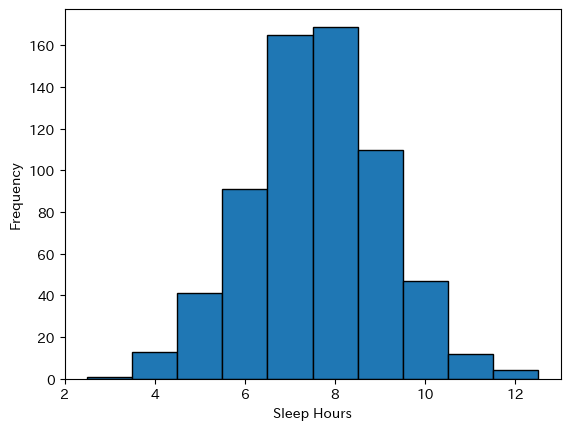

In [15]:
plt.hist(df["Hours_of_sleep"], bins=10, edgecolor="black")
plt.xlabel("Sleep Hours")
plt.ylabel("Frequency")
plt.title("")

/var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/ipykernel_66191/4254805779.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Gender", y="Hours_of_sleep", data=df, palette="pastel")


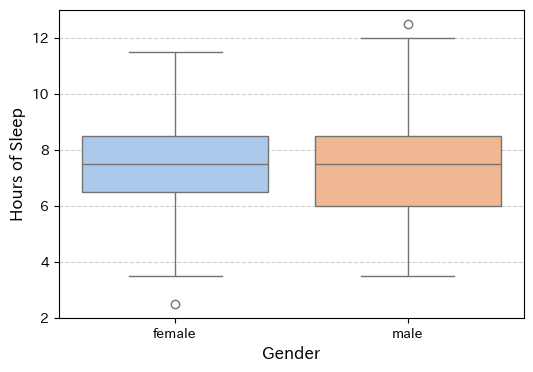

In [16]:
plt.figure(figsize=(6,4))
sns.boxplot(x="Gender", y="Hours_of_sleep", data=df, palette="pastel")

plt.ylabel("Hours of Sleep", fontsize=12)
plt.xlabel("Gender", fontsize=12)
plt.title("")
plt.grid(axis="y", linestyle="--", alpha=0.6)

In [17]:
female_Haircut = df.loc[df["Gender"] == "female","Haircut"]
female_Haircut.describe()

count    416.000000
mean      34.081466
std       30.435079
min        0.000000
25%       15.000000
50%       25.000000
75%       45.000000
max      180.000000
Name: Haircut, dtype: float64

In [18]:
male_Haircut = df.loc[df["Gender"] == "male","Haircut"]
male_Haircut.describe()

count    221.000000
mean      10.536109
std        8.347169
min        0.000000
25%        0.000000
50%       12.000000
75%       15.000000
max       75.000000
Name: Haircut, dtype: float64

## 学生の睡眠の長さは就寝時間と関連性があるだろうか？

最小二乗法による直線を加えた学生の就寝時間と睡眠時間の散布図

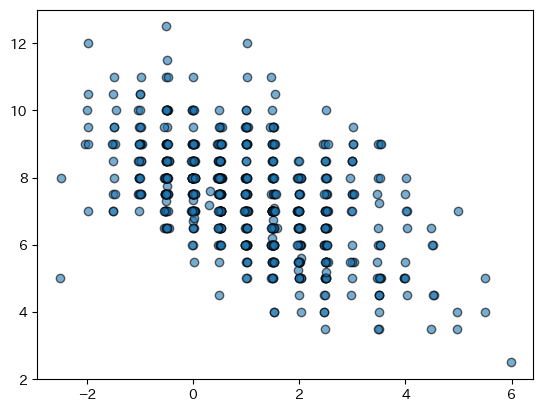

In [19]:
def jitter(arr, amount=0):
    return arr + np.random.normal(0, amount, len(arr))

plt.scatter(
    jitter(df["ToSleep"],0.02),
    jitter(df["Hours_of_sleep"]),
    alpha=0.6, edgecolors="black"
)

In [20]:
import statsmodels.formula.api as smf

fit = smf.ols('Hours_of_sleep ~ ToSleep', data=df).fit()

fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         Hours_of_sleep   R-squared:                       0.282
Model:                            OLS   Adj. R-squared:                  0.281
Method:                 Least Squares   F-statistic:                     256.0
Date:                Sun, 14 Dec 2025   Prob (F-statistic):           7.67e-49
Time:                        18:06:56   Log-Likelihood:                -1087.7
No. Observations:                 653   AIC:                             2179.
Df Residuals:                     651   BIC:                             2188.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.9628      0.062    128.851      0.000       7.841       8.084
ToSleep       -0.5753      0.036    -16.001      0.000      -0.646      -0.505
==============================================================================
Omnibus:                       17.582   Durbin-Watson:                   1.611
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               18.257
Skew:                           0.394   Prob(JB):                     0.000109
Kurtosis:                       3.225   Cond. No.                         2.42
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

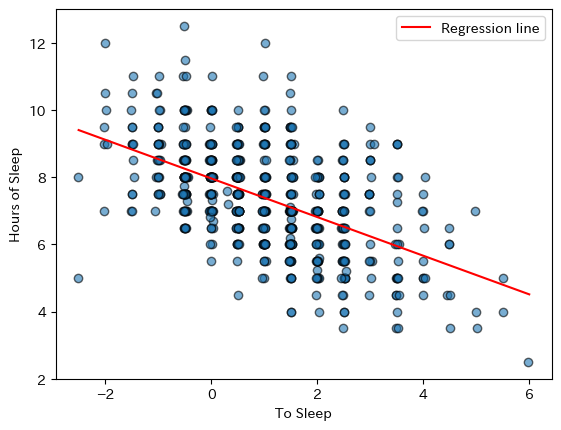

In [21]:
plt.scatter(
    jitter(df["ToSleep"],0.02),
    jitter(df["Hours_of_sleep"]),
    alpha=0.6, edgecolors="black"
)

x_vals = np.linspace(df["ToSleep"].min(), df["ToSleep"].max(), 100)
y_vals = fit.params["Intercept"] + fit.params["ToSleep"] * x_vals
plt.plot(x_vals, y_vals, color="red", label="Regression line")

plt.xlabel("To Sleep")
plt.ylabel("Hours of Sleep")
plt.legend()

## t検定量の頑健性を探る

仮説

$ H_0 : \mu_x = \mu_y $

検定統計量 $ T $

$ T = (\bar{X} - \bar{Y}) / sp \sqrt{1/m + 1/n} \qquad sp = \sqrt{((m-1)s_x^2 + (n-1)s_y^2)/(m+n-2)} $

In [22]:
import numpy as np

def tstatistic(x, y):
    x, y = np.asarray(x), np.asarray(y)
    sp = np.sqrt(((x.size - 1)*x.var(ddof=1) + (y.size - 1)*y.var(ddof=1)) / (x.size + y.size - 2))
    return (x.mean() - y.mean()) / (sp * np.sqrt(1/x.size + 1/y.size))


In [23]:
x = [1,4,3,6,5]
y = [5,4,7,6,10]

tstatistic(x,y)

np.float64(-1.9379255804998181)

In [24]:
from scipy.stats import ttest_ind

t_stat, p_val = ttest_ind(x, y, equal_var=True)
print(t_stat)


-1.9379255804998181


## モンテカルシミュレーション


母集団が正規分布と等分散の標準的な仮説に従わない場合、ｔ検定量の真の優位水準がどうなるかを調べる。

一般に真の有意水準は次の条件に依存する。

* あらかじめ定めた有意水準 $ \alpha $

* 母集団の形状（正規分布か歪んでいるか、あるいは裾が重いかなど）

* 二つの標準偏差ではかられる二つの母集団の広がり方

* 標本サイズ $ m $ と $ n $

真の有意水準の推定

$ \alpha^T = P(|T| \geq t_{n+m-2, \alpha/2 }) $

計算のシュミレーションアルゴリズム

1. ランダム標本 $ x_1, ..., x_m $ を第１母集団から、 $ y_1, ..., y_n $ を第２母集団からシュミレーションする。

2. 二つの標本から t推定量Tを計算する。

3. |T|が棄却域を超えているかを判定し、超えていれば $ H_0 $ を棄却する。

In [25]:
alpha = 0.1
m = 10
n = 10
N = 10000

df = n + m -2

In [26]:
from scipy import stats

t_value = stats.t.ppf(1-alpha/2,df)
t_value

np.float64(1.7340636066175354)

### 1.3.4 異なる仮説下での真の有意水準の挙動

* 平均０で広がりが等しい正規分布

In [27]:
def monte(s_x,s_y):
    n_reject = 0

    for i in np.arange(N):
        x = np.random.normal(loc=0, scale=s_x, size=m)
        y = np.random.normal(loc=0, scale=s_y, size=n)

        t_stat, _ = ttest_ind(x,y,equal_var=True)
        if abs(t_stat) > t_value:
            n_reject += 1

    return (n_reject/N)

* 平均０で広がり方が大きく異なる正規分布

* 自由度４で広がり方の等しいT母集団

In [28]:
def monte2(df_x,df_y):
    n_reject = 0

    for i in np.arange(N):
        x = stats.t.rvs(df=df_x, size=m)
        y = stats.t.rvs(df=df_y, size=n)

        t_stat, P_value = ttest_ind(x,y,equal_var=True)
        if abs(t_stat) > t_value:
            n_reject += 1

    return (n_reject/N)

* $ \mu_x = \mu_y = 1 $ の指数母集団

In [29]:
def monte3(scale_x,scale_y):
    n_reject = 0

    for i in np.arange(N):
        x = np.random.exponential(scale=1/scale_x, size=m)
        y = np.random.exponential(scale=1/scale_y,  size=n)

        t_stat, P_value = ttest_ind(x,y,equal_var=True)
        if abs(t_stat) > t_value:
            n_reject += 1

    return (n_reject/N)

* 正規母集団と指数母集団

In [30]:
def monte4(loc_x,s_x,scale_y):
    n_reject = 0

    for i in np.arange(N):
        x = np.random.normal(loc=loc_x, scale=s_x, size=m)
        y = np.random.exponential(scale=1/scale_y,  size=n)

        t_stat, P_value = ttest_ind(x,y,equal_var=True)
        if abs(t_stat) > t_value:
            n_reject += 1

    return (n_reject/N)

In [31]:
print(f"広がり方の等しい正規母集団：{monte(10,10):.4f}")
print(f"広がり方の異なる正規母集団：{monte(1,10):.4f}")
print(f"広がり方の等しい自由度４のｔ分布：{monte2(4,4):.4f}")
print(f"広がり方の等しい指数母集団：{monte3(1,1):.4f}")
print(f"広がり方の異なる正規分布集団と指数母集団：{monte4(10,2,0.1):.4f}")

広がり方の等しい正規母集団：0.1075
広がり方の異なる正規母集団：0.1122
広がり方の等しい自由度４のｔ分布：0.0968
広がり方の等しい指数母集団：0.0997
広がり方の異なる正規分布集団と指数母集団：0.1573


最後のケースでは真の有意水準があらかじめ定めた水準よりも５０％も大きくなっている。
そこで、ｔ統計量のサンプリング分布を求める。

実際のｔ統計量のサンプリング分布が右に歪んでいる。これで真の有意水準が大きくなっていることの説明がつく。

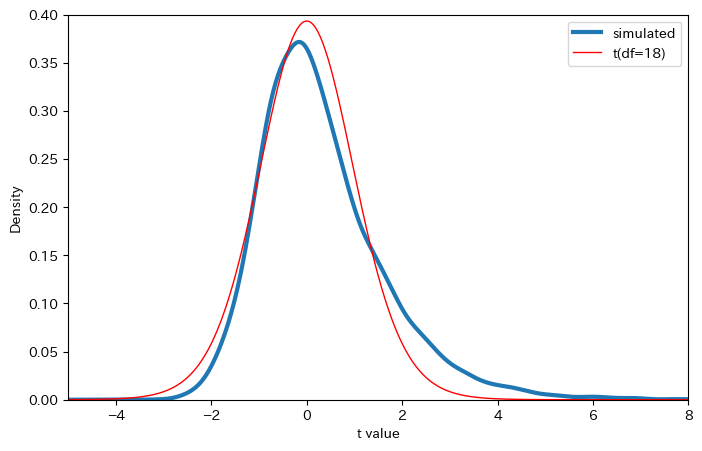

In [32]:
from scipy.stats import gaussian_kde

# サンプルサイズ
m, n = 10, 10
N = 10000

# t統計量計算関数（2標本、等分散仮定）
def tstatistic(x, y):
    x, y = np.asarray(x), np.asarray(y)
    sp = np.sqrt(((x.size - 1)*x.var(ddof=1) + (y.size - 1)*y.var(ddof=1)) / (x.size + y.size - 2))
    return (x.mean() - y.mean()) / (sp * np.sqrt(1/x.size + 1/y.size))

# 1回のシミュレーション
def my_tsimulation():
    x = np.random.normal(loc=10, scale=2, size=m)
    y = np.random.exponential(scale=10, size=n)  # rate=1/10 → scale=10
    return tstatistic(x, y)

# 1000回シミュレーション
tstat_vector = np.array([my_tsimulation() for _ in range(N)])

# 密度推定
density = gaussian_kde(tstat_vector)
x_vals = np.linspace(-5, 8, 500)
y_vals = density(x_vals)

# プロット
plt.figure(figsize=(8,5))
plt.plot(x_vals, y_vals, lw=3, label='simulated')

# 理論 t分布 t(df=18)
df = m + n - 2
plt.plot(x_vals, stats.t.pdf(x_vals, df=df), lw=1, label=f't(df={df})', color='red')

plt.xlim(-5,8)
plt.ylim(0,0.4)
plt.xlabel("t value")
plt.ylabel("Density")
plt.legend()
plt.show()


#  1.6 練習問題


1. 学生たちの所有する映画のDVD

学生データのセットの変数 Dvds には、」受講生が所有している映画のDVDの本数が記録されている。

(a) hist()関数を使ってこの変数のヒストグラムを作成せよ。

(array([547.,  57.,  16.,   9.,   8.,   1.,   0.,   0.,   0.,   0.,   1.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   1.]),
 array([   0.,   50.,  100.,  150.,  200.,  250.,  300.,  350.,  400.,
         450.,  500.,  550.,  600.,  650.,  700.,  750.,  800.,  850.,
         900.,  950., 1000.]),
 <BarContainer object of 20 artists>)

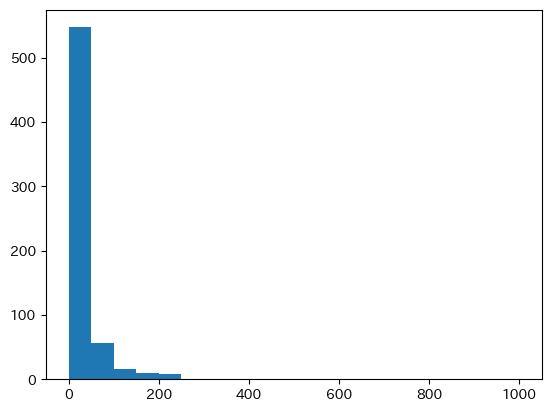

In [33]:
plt.hist(df0["Dvds"],bins=20)

(b) summary()関数を使い、この変数を要約せよ

(c) table() 関数を使って、観測された Dvds の個々の値の頻度表を作成せよ。

回答が特定の値に集中していることがわかる。
DVDの所有本数がこれら特定の値に集中していることに何らかの説明付けができるか？

* 心理的には、「丸め効果」
* 社会的には、「購入パターン・コレクション単位」
* 経済的には、「費用・保管スペースの制約

In [34]:
arr = np.array(df0["Dvds"])

# NaN を除外
arr_clean = arr[~np.isnan(arr)]

# pandas の value_counts で頻度を計算し、大きい順にソート
freq_table = pd.Series(arr_clean).value_counts().sort_values(ascending=False)

print(freq_table[:100])

20.0     83
10.0     78
15.0     46
30.0     45
25.0     31
5.0      27
40.0     26
0.0      26
50.0     26
12.0     20
3.0      18
6.0      14
2.0      13
7.0      12
35.0     12
8.0      12
1.0      10
100.0    10
Name: count, dtype: int64


/var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/ipykernel_66191/2331907211.py:9: FutureWarning: The behavior of obj[i:j] with a float-dtype index is deprecated. In a future version, this will be treated as positional instead of label-based. For label-based slicing, use obj.loc[i:j] instead
  print(freq_table[:100])


2. 睡眠時間

変数 ToSleepとWakeUpにはそれぞれ各学生の前夜の就寝時間と起床時間が記録されている。（データは午前０時からの経過時間であり、例えば -2 というあたいは午後１０時を表している）

(a) ToSleep と WakeUp の散布図を作成せよ。

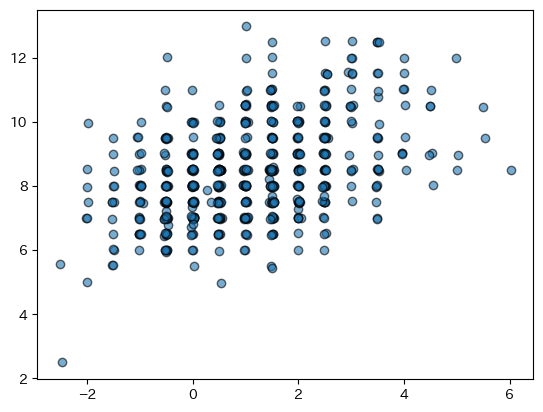

In [35]:
plt.scatter(
    jitter(df0["ToSleep"],0.02),
    jitter(df0["WakeUp"],0.02),
    alpha=0.6, edgecolors="black"
)


(b) lm() 関数を使ってデータに最小二乗法をあてはめよ。

In [36]:
fit = smf.ols('WakeUp ~ ToSleep', data=df0).fit()

fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 WakeUp   R-squared:                       0.177
Model:                            OLS   Adj. R-squared:                  0.175
Method:                 Least Squares   F-statistic:                     139.5
Date:                Sun, 14 Dec 2025   Prob (F-statistic):           2.60e-29
Time:                        18:07:26   Log-Likelihood:                -1087.7
No. Observations:                 653   AIC:                             2179.
Df Residuals:                     651   BIC:                             2188.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.9628      0.062    128.851      0.000       7.841       8.084
ToSleep        0.4247      0.036     11.813      0.000       0.354       0.495
==============================================================================
Omnibus:                       17.582   Durbin-Watson:                   1.611
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               18.257
Skew:                           0.394   Prob(JB):                     0.000109
Kurtosis:                       3.225   Cond. No.                         2.42
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Text(0, 0.5, 'Wakeup')

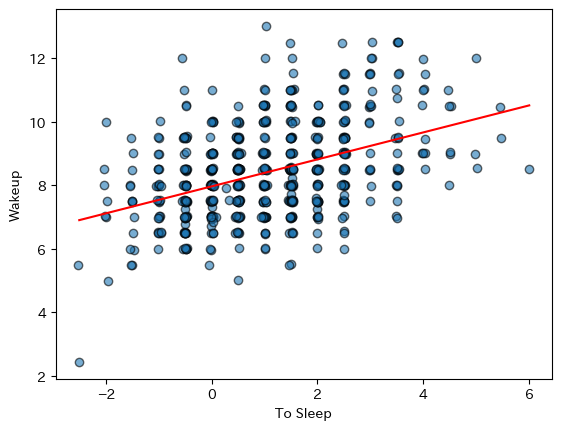

In [37]:
plt.scatter(
    jitter(df0["ToSleep"],0.02),
    jitter(df0["WakeUp"],0.02),
    alpha=0.6, edgecolors="black"
)

x_vals = np.linspace(df0["ToSleep"].min(), df0["ToSleep"].max(), 100)
y_vals = fit.params["Intercept"] + fit.params["ToSleep"] * x_vals
plt.plot(x_vals, y_vals, color="red", label="Regression line")

plt.xlabel("To Sleep")
plt.ylabel("Wakeup")

(d) 回帰直線を利用して、午前0時に就寝した学生の起床時間を予測せよ


In [38]:
from sklearn.linear_model import LinearRegression

df_clean = df0[["ToSleep", "WakeUp"]].dropna().copy()

X = df_clean["ToSleep"].values.reshape(-1, 1)
y = df_clean["WakeUp"].values

model = LinearRegression().fit(X, y)
a = model.coef_[0]
b = model.intercept_

predicted = model.predict(np.array([[0]]))[0]

print(f"午前0時に就寝した学生の予測起床時刻: {predicted:.2f} 時")


午前0時に就寝した学生の予測起床時刻: 7.96 時


## 3.割合についての伝統的な信頼区間の作成１

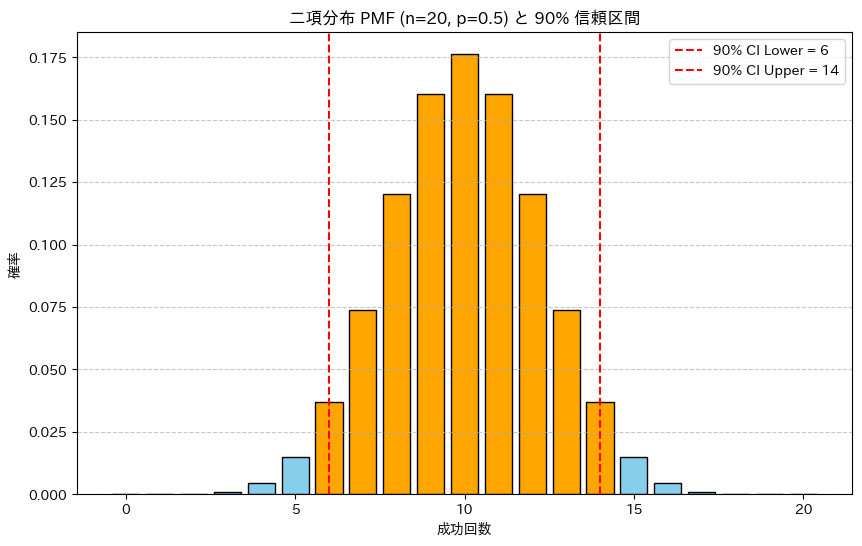

90% 信頼区間: 6 ～ 14 成功回数


In [39]:
from scipy.stats import binom

# パラメータ
n = 20
p = 0.5

# x軸（成功回数）
x = np.arange(0, n+1)

# 二項分布の確率質量関数
pmf = binom.pmf(x, n, p)

# 90%信頼区間
alpha = 0.10
lower = binom.ppf(alpha/2, n, p)  # 下側端点
upper = binom.ppf(1 - alpha/2, n, p)  # 上側端点

# 描画
plt.figure(figsize=(10,6))
colors = ['orange' if lower <= k <= upper else 'skyblue' for k in x]
plt.bar(x, pmf, color=colors, edgecolor='black')

# 信頼区間を強調
plt.axvline(lower, color='red', linestyle='--', label=f'90% CI Lower = {int(lower)}')
plt.axvline(upper, color='red', linestyle='--', label=f'90% CI Upper = {int(upper)}')

plt.xlabel("成功回数")
plt.ylabel("確率")
plt.title(f"二項分布 PMF (n={n}, p={p}) と 90% 信頼区間")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 信頼区間の表示
print(f"90% 信頼区間: {int(lower)} ～ {int(upper)} 成功回数")


標本サイズがn=20,割合の真の値がp=0.5であると仮定

Rのbinomial.conf.interval()関数をつかって90%信頼区間を計算する操作を20回繰り返し、$ P(p \in C(y)) $の範囲の真の確率を計算せよ。

Rのbinomial.conf.interval()は、二項分布の信頼区間を計算する関数。

In [40]:
import numpy as np
from statsmodels.stats.proportion import proportion_confint

# パラメータ
n = 20       # 標本サイズ
p_true = 0.5 # 真の成功確率
alpha = 0.10 # 90%信頼区間
num_trials = 20

# 真の確率が信頼区間に入る回数をカウント
count_inside = 0

for i in range(num_trials):
    # 標本を生成（成功回数）
    x = np.random.binomial(n, p_true)
    
    # 90%信頼区間（Wilson法）
    lower, upper = proportion_confint(x, n, alpha=alpha, method='wilson')
    
    # 真の確率 p_true が信頼区間に入っているかチェック
    if lower <= p_true <= upper:
        count_inside += 1
    
    print(f"試行{i+1}: x={x}, CI=({lower:.3f}, {upper:.3f}), p_true={p_true}, 入っているか: {lower <= p_true <= upper}")

# 20回中の割合（P(p_trueがCI内に入る確率）
prob_inside = count_inside / num_trials
print(f"\n20回中 {count_inside} 回、真のp={p_true} が90% CIに入った")
print(f"PがCI内に入る確率の推定値 = {prob_inside:.2f})")


試行1: x=9, CI=(0.284, 0.628), p_true=0.5, 入っているか: True
試行2: x=15, CI=(0.568, 0.873), p_true=0.5, 入っているか: False
試行3: x=10, CI=(0.327, 0.673), p_true=0.5, 入っているか: True
試行4: x=8, CI=(0.242, 0.581), p_true=0.5, 入っているか: True
試行5: x=12, CI=(0.419, 0.758), p_true=0.5, 入っているか: True
試行6: x=10, CI=(0.327, 0.673), p_true=0.5, 入っているか: True
試行7: x=4, CI=(0.093, 0.378), p_true=0.5, 入っているか: False
試行8: x=11, CI=(0.372, 0.716), p_true=0.5, 入っているか: True
試行9: x=11, CI=(0.372, 0.716), p_true=0.5, 入っているか: True
試行10: x=10, CI=(0.327, 0.673), p_true=0.5, 入っているか: True
試行11: x=10, CI=(0.327, 0.673), p_true=0.5, 入っているか: True
試行12: x=9, CI=(0.284, 0.628), p_true=0.5, 入っているか: True
試行13: x=13, CI=(0.467, 0.798), p_true=0.5, 入っているか: True
試行14: x=12, CI=(0.419, 0.758), p_true=0.5, 入っているか: True
試行15: x=13, CI=(0.467, 0.798), p_true=0.5, 入っているか: True
試行16: x=10, CI=(0.327, 0.673), p_true=0.5, 入っているか: True
試行17: x=12, CI=(0.419, 0.758), p_true=0.5, 入っているか: True
試行18: x=12, CI=(0.419, 0.758), p_true=0.5, 入っているか: True
試行1

n=20で割合の真の値がp=0.05である二項分布に従うランダムな変数を２０個シュミレーションする。

また、シュミレーションされた個々の値ｙについて９０％信頼区間の計算しその範囲の真の確率を計算する。

In [41]:
# パラメータ
n = 20        # 標本サイズ
p_true = 0.05 # 真の成功確率
alpha = 0.10  # 90%信頼区間
num_simulations = 20

# 真のpが信頼区間に入る回数
count_inside = 0

# 20回シミュレーション
for i in range(num_simulations):
    # 二項分布に従うランダムな成功回数
    y = np.random.binomial(n, p_true)
    
    # 90%信頼区間（Wilson法）
    lower, upper = proportion_confint(y, n, alpha=alpha, method='wilson')
    
    # 真のpが信頼区間に入るか
    is_inside = lower <= p_true <= upper
    if is_inside:
        count_inside += 1
    
    print(f"シミュレーション {i+1}: y={y}, CI=({lower:.3f}, {upper:.3f}), p_true={p_true}, CI内か? {is_inside}")

# 20回中の確率
prob_inside = count_inside / num_simulations
print(f"\n20回中 {count_inside} 回、真のp={p_true} が90% CIに入った")
print(f"PがCI内に入る確率の推定値 = {prob_inside:.2f})")


シミュレーション 1: y=1, CI=(0.011, 0.196), p_true=0.05, CI内か? True
シミュレーション 2: y=0, CI=(0.000, 0.119), p_true=0.05, CI内か? True
シミュレーション 3: y=2, CI=(0.034, 0.262), p_true=0.05, CI内か? True
シミュレーション 4: y=0, CI=(0.000, 0.119), p_true=0.05, CI内か? True
シミュレーション 5: y=1, CI=(0.011, 0.196), p_true=0.05, CI内か? True
シミュレーション 6: y=2, CI=(0.034, 0.262), p_true=0.05, CI内か? True
シミュレーション 7: y=1, CI=(0.011, 0.196), p_true=0.05, CI内か? True
シミュレーション 8: y=2, CI=(0.034, 0.262), p_true=0.05, CI内か? True
シミュレーション 9: y=1, CI=(0.011, 0.196), p_true=0.05, CI内か? True
シミュレーション 10: y=4, CI=(0.093, 0.378), p_true=0.05, CI内か? False
シミュレーション 11: y=1, CI=(0.011, 0.196), p_true=0.05, CI内か? True
シミュレーション 12: y=0, CI=(0.000, 0.119), p_true=0.05, CI内か? True
シミュレーション 13: y=0, CI=(0.000, 0.119), p_true=0.05, CI内か? True
シミュレーション 14: y=2, CI=(0.034, 0.262), p_true=0.05, CI内か? True
シミュレーション 15: y=1, CI=(0.011, 0.196), p_true=0.05, CI内か? True
シミュレーション 16: y=0, CI=(0.000, 0.119), p_true=0.05, CI内か? True
シミュレーション 17: y=0, CI=(0.000, 0.1

## 4.割合についての伝統的な信頼区間の作成２

モンテカルロ法をつかって範囲の確率が標本サイズと真の割合の値に依存するかを調べる。

n=10, 25, 100にp=0.05, 0.25, 0.50に変化させる。

モンテカルロシュミレーション数はｍ=1000とし、様々な組み合わせで、伝統的な区間による実際の範囲確率が標本サイズと真の割合の値にどのように依存しているか説明する。

In [42]:
# パラメータ
sample_sizes = [10, 25, 100]   # n
true_ps = [0.05, 0.25, 0.5]    # p
alpha = 0.10                   # 90%信頼区間
m = 1000                       # モンテカルロ試行回数

# 結果を保存するリスト
results = []

for n in sample_sizes:
    for p_true in true_ps:
        count_inside = 0
        for _ in range(m):
            # 二項分布から標本を生成
            x = np.random.binomial(n, p_true)
            # Wilson法で90%信頼区間を計算
            lower, upper = proportion_confint(x, n, alpha=alpha, method='wilson')
            # 真のpがCIに入っているか
            if lower <= p_true <= upper:
                count_inside += 1
        # 実際の範囲確率（p_trueがCIに入った割合）
        coverage_prob = count_inside / m
        results.append({'n': n, 'p_true': p_true, 'coverage_prob': coverage_prob})

# データフレーム化して表示
df_results = pd.DataFrame(results)
print(df_results.pivot(index='n', columns='p_true', values='coverage_prob'))


p_true   0.05   0.25   0.50
n                          
10      0.906  0.876  0.892
25      0.962  0.897  0.882
100     0.881  0.908  0.885


1. 標本サイズが小さいほど実際の範囲確率は90%から外れやすい。
2. pが0.5に近いと、CIのカバー率はより安定して90%に近くなる。
3. 標本サイズが大きくなると、ほぼ理論通りの90%範囲確率に近づく。